This notebook reads two Cells files and plots their ratio

In [ ]:
# General imports
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from copy import deepcopy
import os
import time
import astropy.io.fits as fits
from scipy import interpolate
from scipy import integrate
from scipy.ndimage import gaussian_filter1d

# Euclid imports
from cloelib.cosmology.camb_cosmology import CAMBBackground, CAMBLinearPerturbations, CAMBNonLinearPerturbations
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint
import euclidlib as el
from cloelike.EuclidLikelihood_photo_Cls import EuclidLikelihood_WL

import heracles

import seaborn as sns
sns.set_theme(style='ticks')
sns.set_palette(sns.color_palette("Paired"))
#plt.style.use('/Users/jcoloma/phd/ice/euclid/beautiful_plots.mplstyle')

In [6]:
path =  '/Users/jcoloma/phd/ice/euclid/cosmosis_vs_cloe/draft/files/cloelib/'

cells_A = heracles.read(path + 'cells_cloelib_A.fits')
cells_B = heracles.read(path + 'cells_cloelib_B.fits')

ells = cells_A[('SHE', 'SHE', 1, 1)].ell

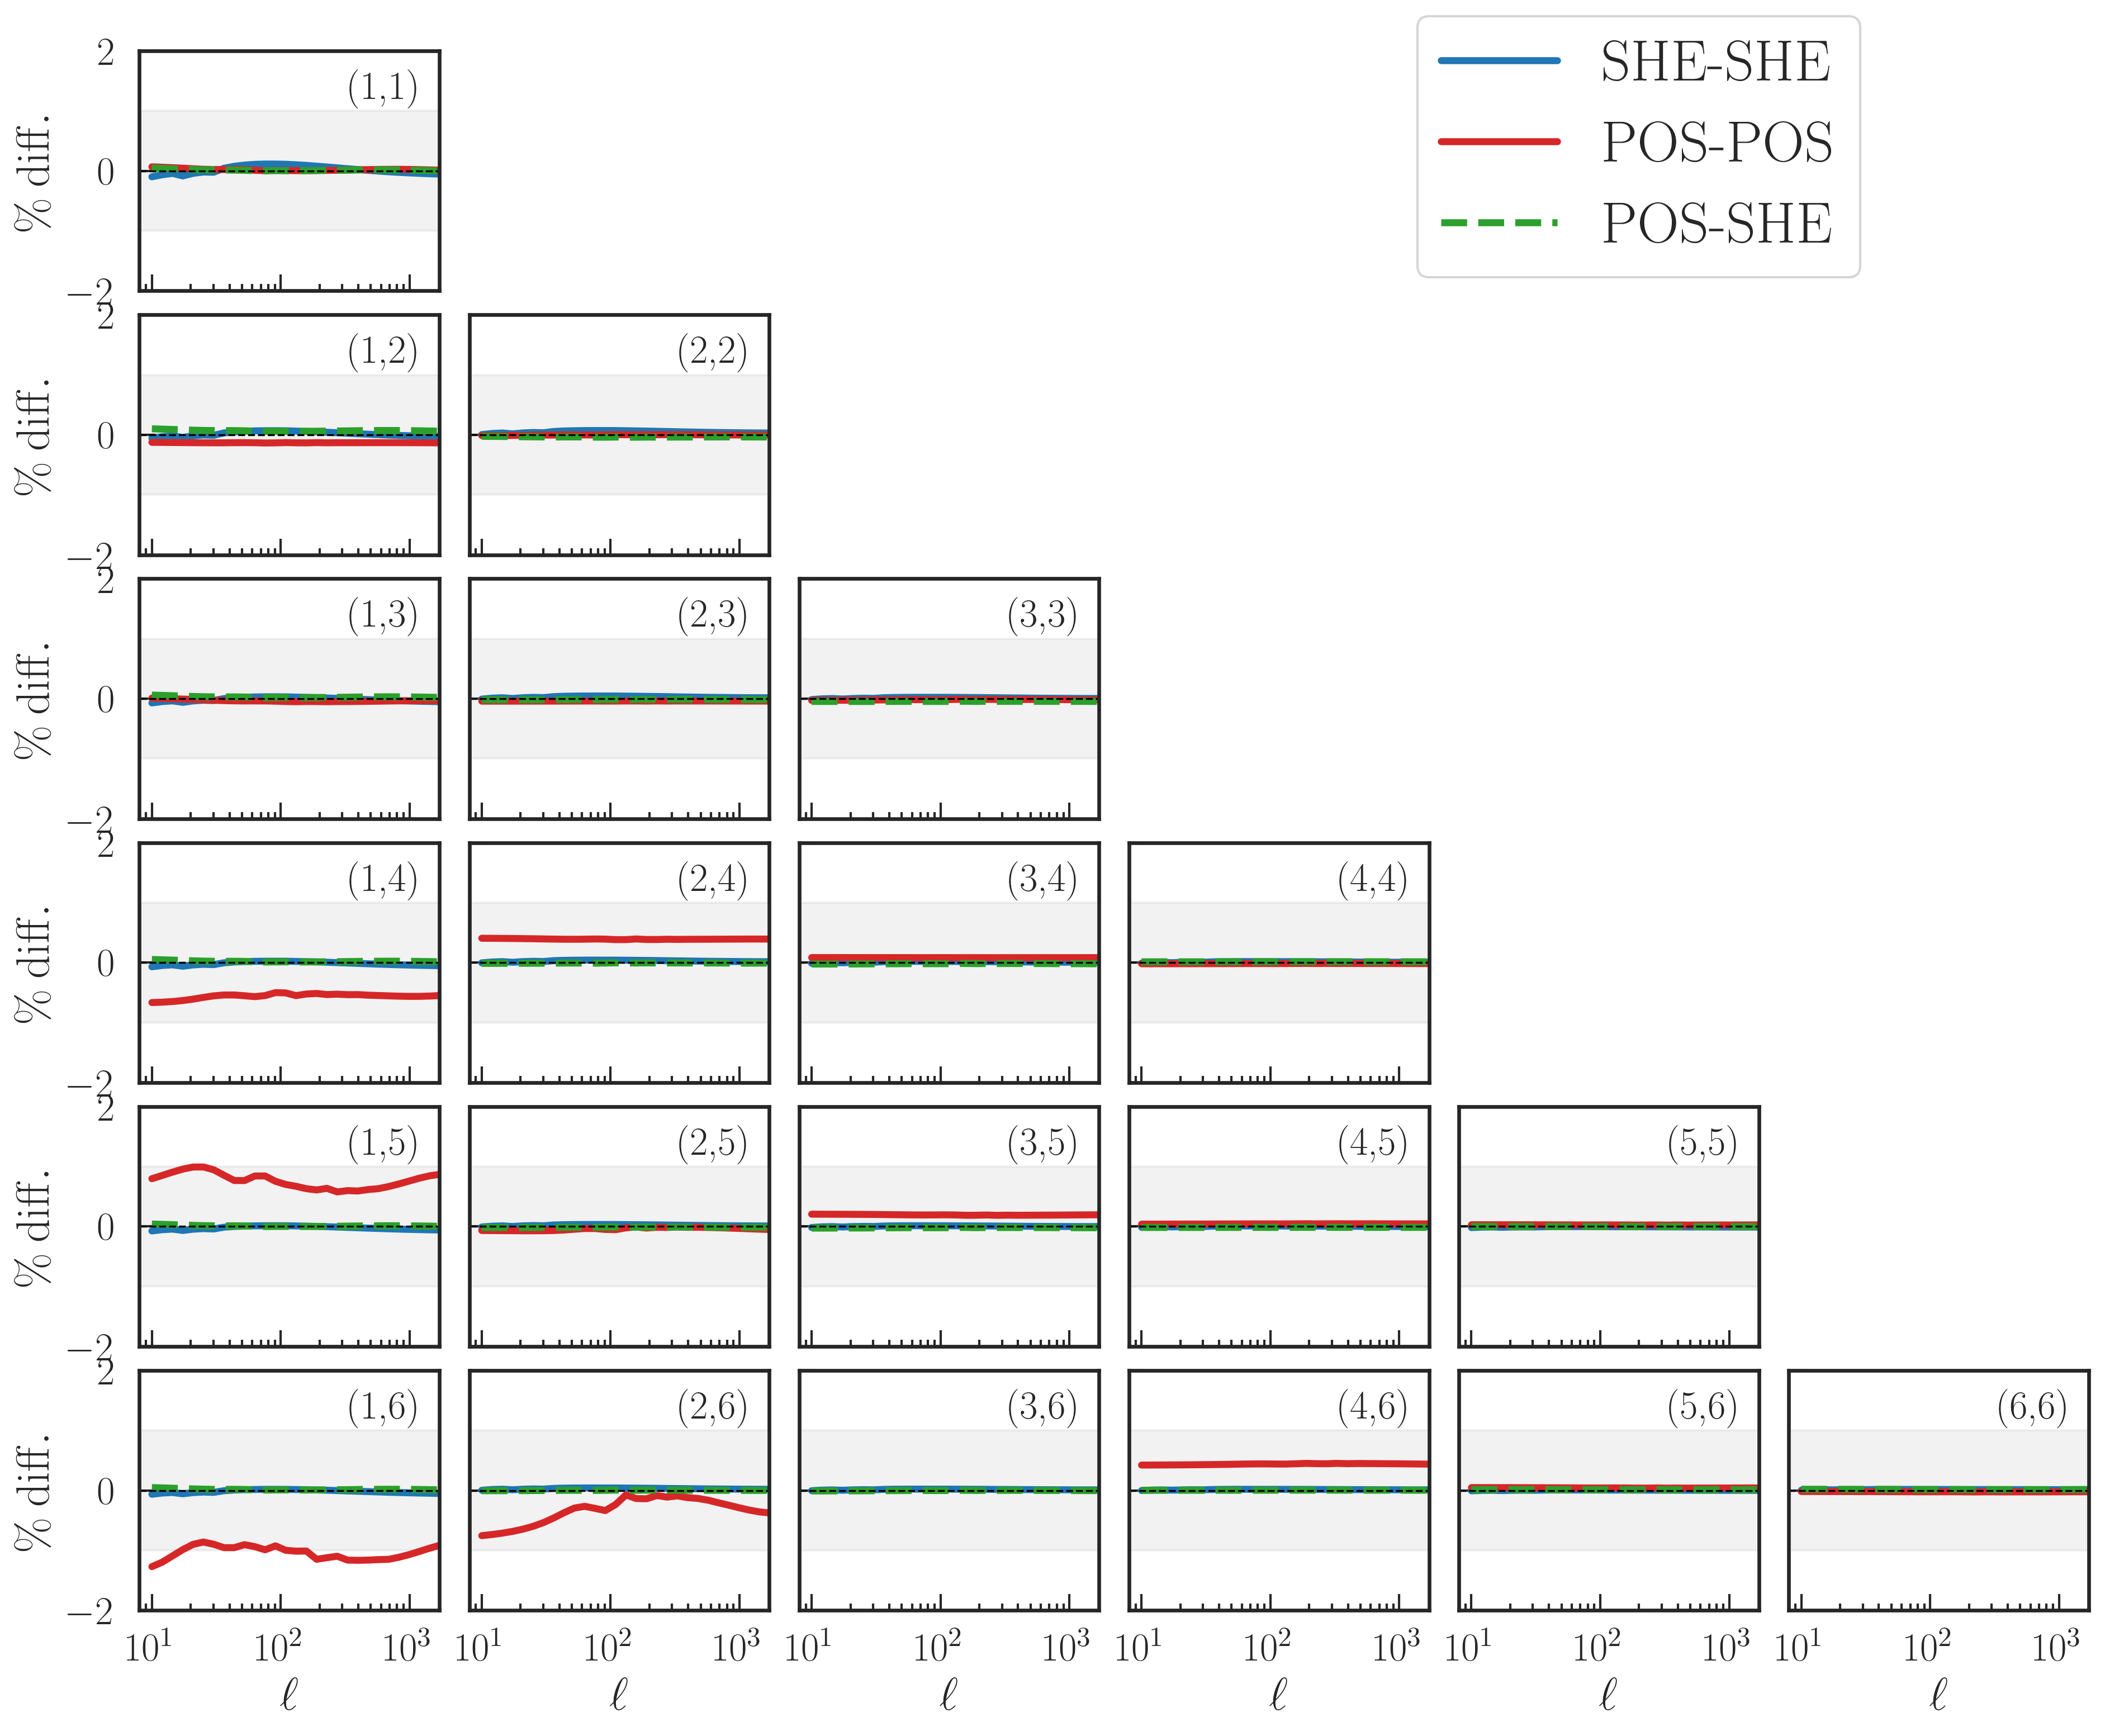

In [7]:
fig, axs = plt.subplots(6, 6, figsize=(15,12), sharey=True, sharex=True)
fig.subplots_adjust(wspace=0.1, hspace=0.1)

cells_ref = cells_B
cells = cells_A

for i in range(6):
    for j in range(i, 6, 1):
        # Cells ratio
        axs[j,i].plot(ells, (cells[('SHE', 'SHE', i+1, j+1)][0,0]-cells_ref[('SHE', 'SHE', i+1, j+1)][0,0])/cells_ref[('SHE', 'SHE', i+1, j+1)][0,0]*100
           , color='tab:blue', lw=3, ls='-', zorder=2, label='SHE-SHE')

        axs[j,i].plot(ells, (cells[('POS', 'POS', i+1, j+1)][:]-cells_ref[('POS', 'POS', i+1, j+1)][:])/cells_ref[('POS', 'POS', i+1, j+1)][:]*100
            , color='tab:red', lw=3, ls='-', zorder=2, label='POS-POS')

        axs[j,i].plot(ells, (cells[('POS', 'SHE', i+1, j+1)][0]-cells_ref[('POS', 'SHE', i+1, j+1)][0])/cells_ref[('POS', 'SHE', i+1, j+1)][0]*100
            , color='tab:green', lw=3, ls='--', zorder=2, label='POS-SHE')


for i in range(6):
    for j in range(6):
        axs[j,i].set_xscale('log')

        axs[j,i].axhline(0, lw=.8, ls='--', color='black')
        
        axs[i,0].set_ylabel(r'$\%\: \rm{diff.}$', fontsize=20)
        axs[-1,j].set_xlabel(r'$\ell$', fontsize=20)

        axs[j,i].text(0.7, 0.8, f'({i+1},{j+1})', transform=axs[j,i].transAxes, fontsize=17)

        axs[j,i].tick_params(labelsize= 17)
        axs[j,i].tick_params(direction='in', which='major', length=7, width=1., pad=10, top=False, right=False)
        axs[j,i].tick_params(direction='in', which='minor', length=3, width=1, pad=10, top=False, right=False)

        axs[j,i].set_xlim([8,1700])
        axs[j,i].set_ylim([-2, 2])
        axs[j,i].fill_between((0, 3000), -1, 1, color='grey', alpha=0.1, zorder=0)

for i in range(6):
    for j in range(i+1,6,1):
        axs[i,j].remove()

axs[0,0].legend(loc='center', bbox_to_anchor=(5, .6), fontsize=25)
#fig.suptitle('Interpolating n(z): 3 vs. 1')
plt.show()       

In [8]:
path_out = '/Users/jcoloma/phd/ice/euclid/cosmosis_vs_cloe/draft/plots/interpolate/'
saveplots = False
if saveplots:
    fig.savefig(path_out + 'cells_IA_256-1000.png',
                dpi=400,
                bbox_inches='tight',
                pad_inches=0.3)
